# Robot run metrics

Visualizations for batch evaluation runs exported in `metrics.json`: session-level aggregates and per-run accuracy, timing, and recovery behavior.

In [16]:
from pathlib import Path

import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

NOTEBOOK_DIR = Path(".").resolve()
METRICS_PATH = NOTEBOOK_DIR / "metrics.json"

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

SCENARIO_PALETTE = {
    "baseline": "#4C72B0",
    "live_recovery": "#DD8452",
    "offline_recovery": "#55A868",
    "unknown": "#8172B3",
}

In [17]:
with METRICS_PATH.open(encoding="utf-8") as f:
    metrics = json.load(f)

session = metrics["session"]
runs_df = pd.DataFrame(metrics["runs"])
runs_df["task_complete"] = runs_df["task_complete"].astype(bool)
runs_df["label"] = runs_df.apply(
    lambda r: r["run_id"] if len(r["scenario"]) > 40 else r["scenario"],
    axis=1,
)

print(f"Loaded {len(runs_df)} runs from {METRICS_PATH.name}")
runs_df[["run_id", "scenario_kind", "task_complete", "cycle_time_s_est"]].head()

Loaded 7 runs from metrics.json


,run_id,scenario_kind,task_complete,cycle_time_s_est
0,baseline_01,baseline,True,55.2
1,baseline_02,baseline,True,55.2
2,live_drop_pick2,live_recovery,True,64.4
3,live_drop_pick4,live_recovery,True,64.4
4,live_offset_pick0,live_recovery,True,64.4


## Session summary

Aggregate KPIs across all runs in the batch.

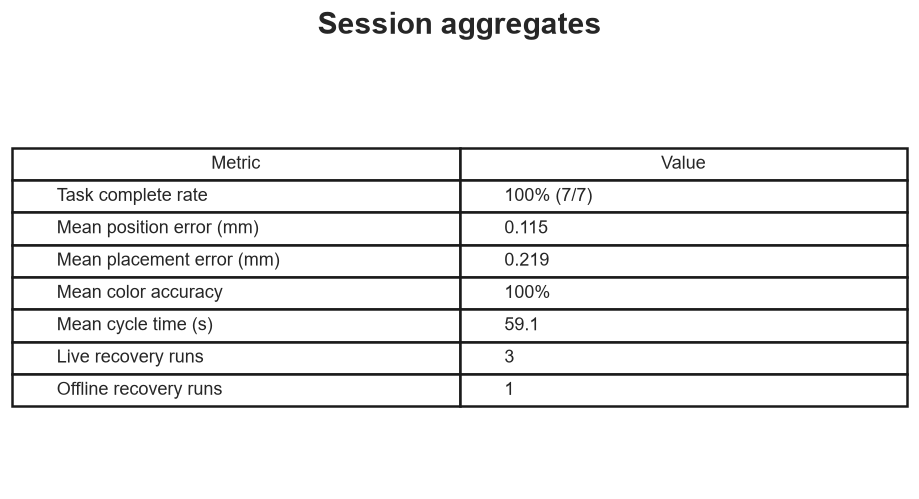

In [18]:
kpi_rows = [
    ("Task complete rate", f"{session['task_complete_rate']:.0%} ({session['task_complete_count']}/{session['run_count']})"),
    ("Mean position error (mm)", f"{session['position_error_mm_mean']:.3f}"),
    ("Mean placement error (mm)", f"{session['placement_error_mm_mean']:.3f}"),
    ("Mean color accuracy", f"{session['colour_accuracy_mean']:.0%}"),
    ("Mean cycle time (s)", f"{session['cycle_time_s_mean']:.1f}"),
    ("Live recovery runs", str(session["live_recovery_runs"])),
    ("Offline recovery runs", str(session["offline_recovery_runs"])),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")
table = ax.table(
    cellText=[[name, value] for name, value in kpi_rows],
    colLabels=["Metric", "Value"],
    loc="center",
    cellLoc="left",
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)
ax.set_title("Session aggregates", pad=20, fontweight="bold")
plt.tight_layout()
plt.savefig('aggregates.png')
plt.show()

## Task completion and pick execution

Whether each run finished the stack and how many picks were verified vs planned.

C:\Users\kwaterskip\AppData\Local\Temp\ipykernel_31736\1354981749.py:27: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\kwaterskip\innyvinny\rockwell-nvidia-hackathon\tutorials\notebooks\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


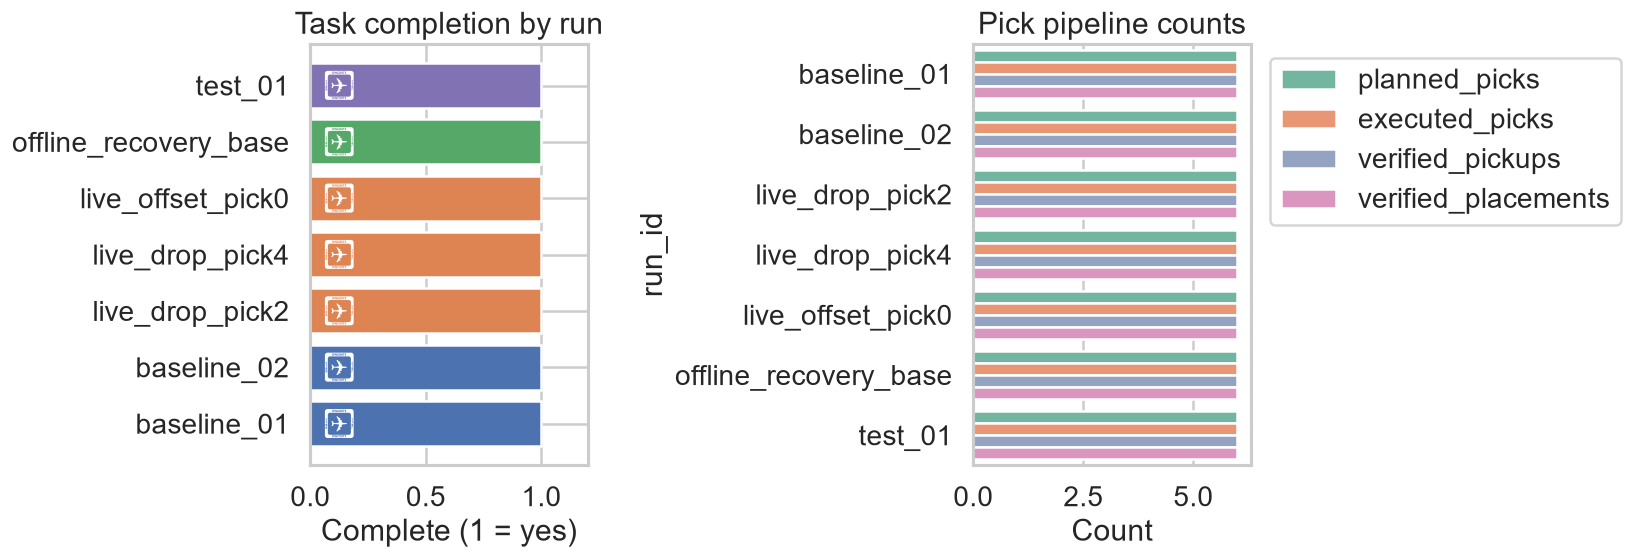

In [19]:
order = runs_df.sort_values("scenario_kind").reset_index(drop=True)
colors = order["scenario_kind"].map(SCENARIO_PALETTE).fillna("#999999")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(order["run_id"], order["task_complete"].astype(int), color=colors)
axes[0].set_xlim(0, 1.2)
axes[0].set_xlabel("Complete (1 = yes)")
axes[0].set_title("Task completion by run")
for i, complete in enumerate(order["task_complete"]):
    axes[0].text(0.05, i, "✓" if complete else "✗", va="center", color="white", fontweight="bold")

pick_cols = ["planned_picks", "executed_picks", "verified_pickups", "verified_placements"]
pick_melt = order.melt(id_vars=["run_id", "scenario_kind"], value_vars=pick_cols, var_name="stage", value_name="count")
sns.barplot(
    data=pick_melt,
    y="run_id",
    x="count",
    hue="stage",
    ax=axes[1],
    palette="Set2",
)
axes[1].set_title("Pick pipeline counts")
axes[1].legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig('pipeline_counts.png')
plt.show()

## Accuracy and timing

Position error (grasp), placement error, colour accuracy, and estimated cycle time per run.

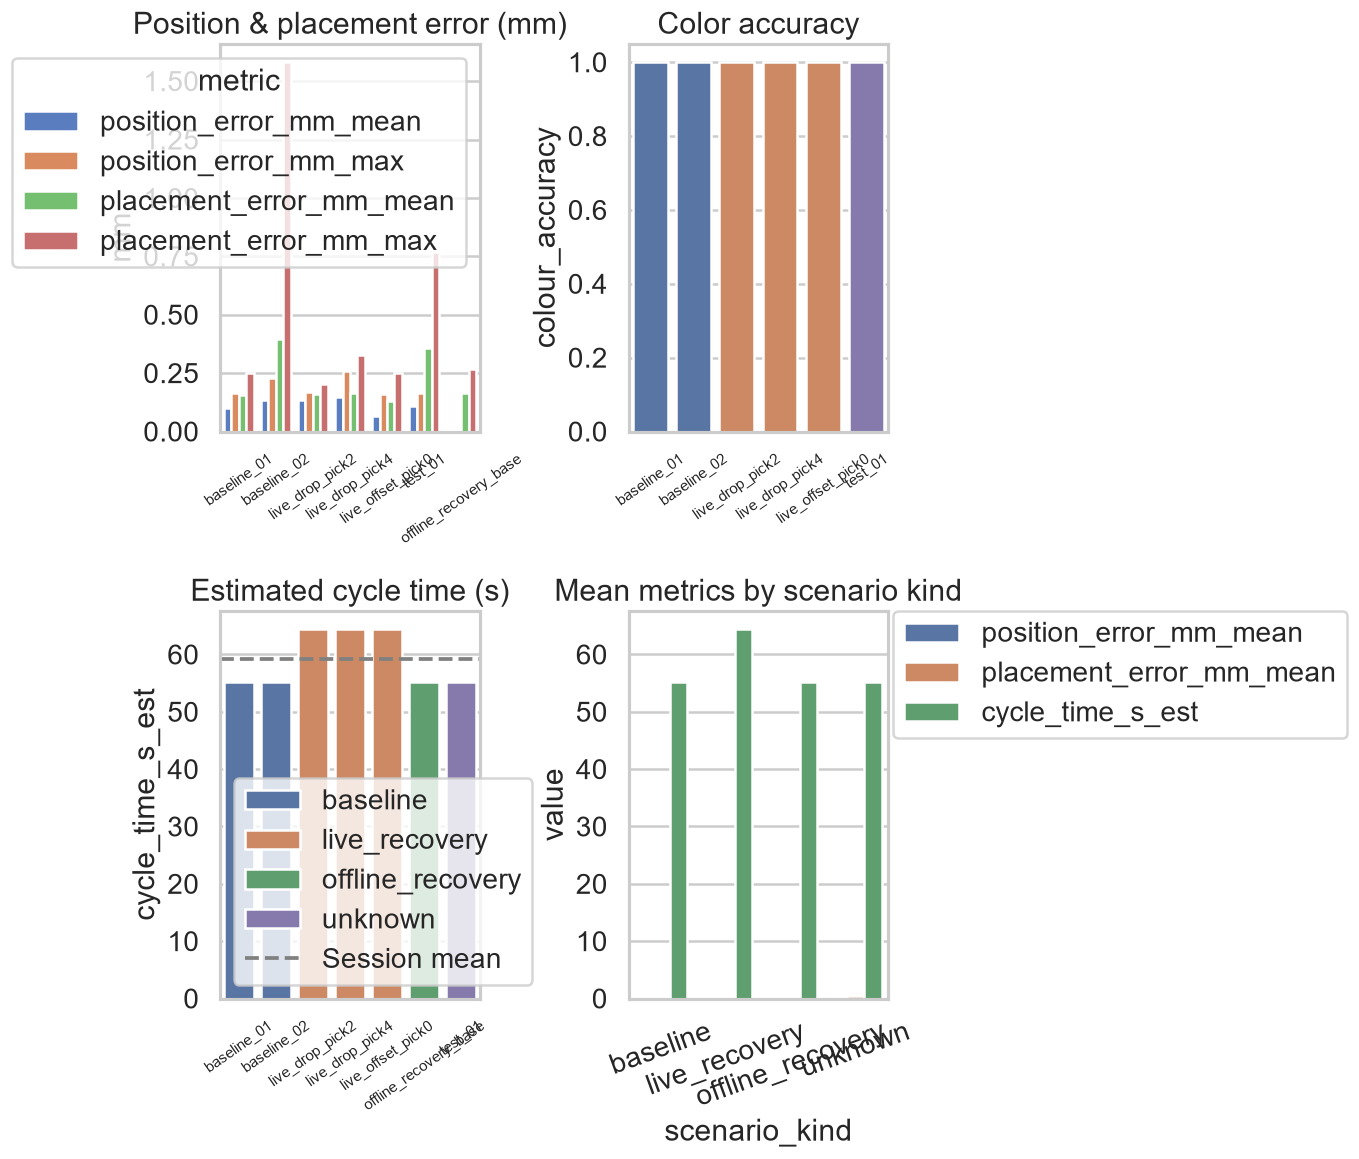

In [20]:
error_cols = [
    "position_error_mm_mean",
    "position_error_mm_max",
    "placement_error_mm_mean",
    "placement_error_mm_max",
]
error_melt = order.melt(
    id_vars=["run_id", "scenario_kind"],
    value_vars=error_cols,
    var_name="metric",
    value_name="mm",
)
error_melt = error_melt.dropna(subset=["mm"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.barplot(
    data=error_melt,
    x="run_id",
    y="mm",
    hue="metric",
    ax=axes[0, 0],
    palette="muted",
)
axes[0, 0].set_title("Position & placement error (mm)")
axes[0, 0].tick_params(axis="x", rotation=35, labelsize=9)
axes[0, 0].set_xlabel("")

colour_df = order.dropna(subset=["colour_accuracy"])
sns.barplot(
    data=colour_df,
    x="run_id",
    y="colour_accuracy",
    hue="scenario_kind",
    dodge=False,
    ax=axes[0, 1],
    palette=SCENARIO_PALETTE,
)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].set_title("Color accuracy")
axes[0, 1].tick_params(axis="x", rotation=35, labelsize=9)
axes[0, 1].set_xlabel("")
if axes[0, 1].legend_:
    axes[0, 1].legend_.remove()

sns.barplot(
    data=order,
    x="run_id",
    y="cycle_time_s_est",
    hue="scenario_kind",
    dodge=False,
    ax=axes[1, 0],
    palette=SCENARIO_PALETTE,
)
axes[1, 0].axhline(session["cycle_time_s_mean"], ls="--", c="gray", label="Session mean")
axes[1, 0].set_title("Estimated cycle time (s)")
axes[1, 0].tick_params(axis="x", rotation=35, labelsize=9)
axes[1, 0].set_xlabel("")
axes[1, 0].legend()

kind_summary = (
    runs_df.groupby("scenario_kind", as_index=False)[
        ["position_error_mm_mean", "placement_error_mm_mean", "cycle_time_s_est"]
    ]
    .mean(numeric_only=True)
)
kind_melt = kind_summary.melt(id_vars="scenario_kind", var_name="metric", value_name="value")
sns.barplot(
    data=kind_melt,
    x="scenario_kind",
    y="value",
    hue="metric",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Mean metrics by scenario kind")
axes[1, 1].tick_params(axis="x", rotation=20)
sns.move_legend(
    axes[1, 1],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    title="",
)

plt.tight_layout(rect=[0, 0, 0.78, 1])
plt.savefig('metrics.png')
plt.show()

## Recovery scenarios

Live fault injection with on-robot recovery vs offline log replay.

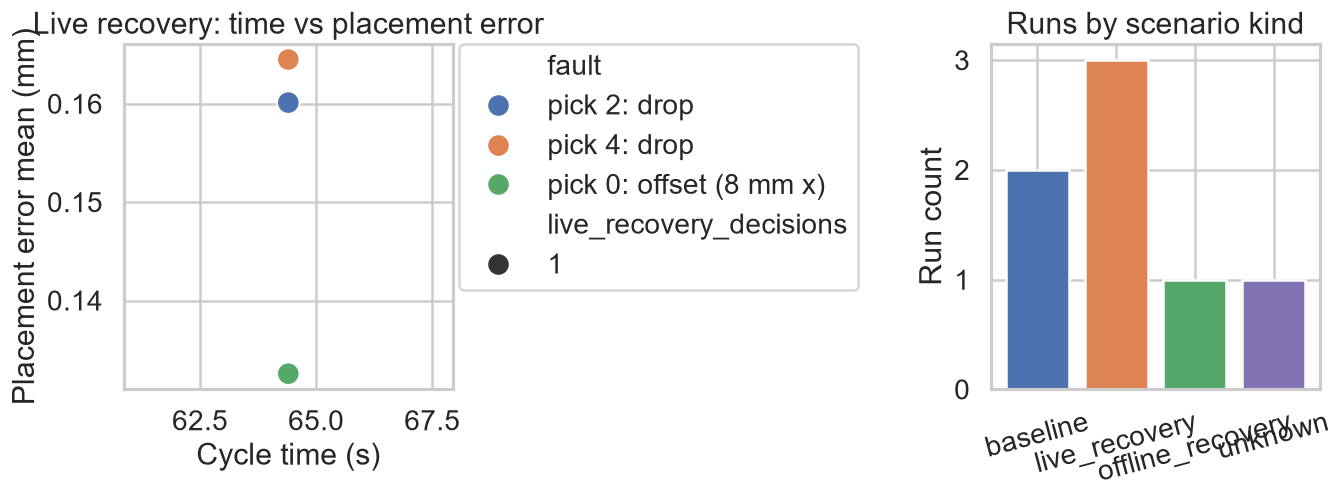

,run_id,scenario,fault,live_recovery_decisions,offline_recovery_log,recovery_final_complete,task_complete
2,live_drop_pick2,Live recovery: accidental drop pick 2,pick 2: drop,1,False,None,True
3,live_drop_pick4,Live recovery: accidental drop pick 4,pick 4: drop,1,False,None,True
4,live_offset_pick0,Live recovery: grasp offset pick 0,pick 0: offset (8 mm x),1,False,None,True
5,offline_recovery_base,Offline recovery replay,offline replay,0,True,True,True


In [21]:
recovery_df = runs_df[
    runs_df["scenario_kind"].isin(["live_recovery", "offline_recovery"])
].copy()

def fault_label(row):
    fault = row.get("injected_fault")
    if not fault or not isinstance(fault, dict):
        if row.get("offline_recovery_log"):
            return "offline replay"
        return "none"
    mode = fault.get("mode", "?")
    pick = fault.get("pick_index", "?")
    if mode == "offset":
        return f"pick {pick}: offset ({fault.get('dx_mm', 0):g} mm x)"
    return f"pick {pick}: {mode}"

recovery_df["fault"] = recovery_df.apply(fault_label, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

live = recovery_df[recovery_df["scenario_kind"] == "live_recovery"]
sns.scatterplot(
    data=live,
    x="cycle_time_s_est",
    y="placement_error_mm_mean",
    hue="fault",
    style="live_recovery_decisions",
    s=180,
    ax=axes[0],
)
axes[0].set_title("Live recovery: time vs placement error")
axes[0].set_xlabel("Cycle time (s)")
axes[0].set_ylabel("Placement error mean (mm)")
sns.move_legend(
    axes[0],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    title="",
)

counts = runs_df.groupby("scenario_kind").size().reindex(
    ["baseline", "live_recovery", "offline_recovery", "unknown"]
).fillna(0)
axes[1].bar(counts.index, counts.values, color=[SCENARIO_PALETTE.get(k, "#999") for k in counts.index])
axes[1].set_title("Runs by scenario kind")
axes[1].set_ylabel("Run count")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig('runs.png')
plt.show()

recovery_df[
    [
        "run_id",
        "scenario",
        "fault",
        "live_recovery_decisions",
        "offline_recovery_log",
        "recovery_final_complete",
        "task_complete",
    ]
]